# **Logistic Regression Practice Notebook**

Dataset: **Titanic** (from the Seaborn library)

This notebook covers:
1. Univariate Logistic Regression
2. Multivariate Logistic Regression

Write your code in the empty cells below each question. Only a **Confusion Matrix** chart is required for each section — no other visualizations.

## **Section 1: Load and Prepare the Dataset**

**Q1.** Import the required libraries (`pandas`, `numpy`, `seaborn`, `matplotlib.pyplot`) and load the `titanic` dataset from Seaborn. Display the first 5 rows.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**Q2.** Check the shape of the dataset, the data types of each column, and the count of missing values in each column.

In [3]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())

Shape: (891, 15)

Data types:
 survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object

Missing values:
 survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


**Q3.** Handle the missing values in the dataset appropriately (choose suitable columns to drop or fill).

In [4]:
df = df.drop(columns=['deck'])
df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])
df = df.dropna()
print(df.isnull().sum().sum(), "missing values left")

0 missing values left


**Q4.** Identify the target variable for this task (`survived`) and confirm it is binary (0/1).

In [5]:
print(df['survived'].unique())
print(df['survived'].value_counts())

[0 1]
survived
0    549
1    342
Name: count, dtype: int64


## **Section 2: Univariate Logistic Regression**

Use a single feature (`fare`) to predict `survived`.

**Q5.** Define `X` using only the `fare` column and `y` using the `survived` column.

In [6]:
X = df[['fare']]
y = df['survived']

**Q6.** Split the data into training and testing sets.

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(712, 1) (179, 1)


**Q7.** Build a Logistic Regression model and train it on the training data.

In [8]:
from sklearn.linear_model import LogisticRegression
model_uni = LogisticRegression()
model_uni.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

**Q8.** Predict the `survived` outcome for the test set.

In [9]:
y_pred_uni = model_uni.predict(X_test)
y_pred_uni[:10]

array([0, 0, 0, 0, 0, 1, 0, 0, 0, 0])

**Q9.** Calculate the accuracy of the model.

In [10]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
acc_uni = accuracy_score(y_test, y_pred_uni)
print("Univariate accuracy:", acc_uni)

Univariate accuracy: 0.6536312849162011


**Q10.** Print the model's coefficient and intercept.

In [11]:
print("Coefficient:", model_uni.coef_)
print("Intercept:", model_uni.intercept_)

Coefficient: [[0.01354448]]
Intercept: [-0.93002768]


**Q11.** Plot the Confusion Matrix for the univariate model. (Only this chart is required for this section — no other visualizations.)

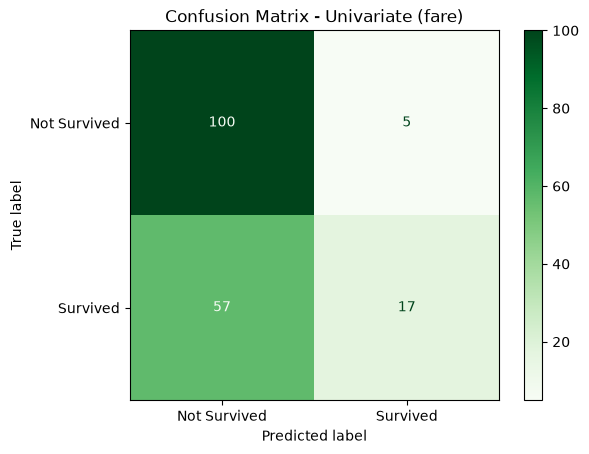

In [12]:
cm_uni = confusion_matrix(y_test, y_pred_uni)
ConfusionMatrixDisplay(cm_uni, display_labels=['Not Survived', 'Survived']).plot(cmap='Greens')
plt.title('Confusion Matrix - Univariate (fare)')
plt.show()

## **Section 3: Multivariate Logistic Regression**

Use multiple features (`pclass`, `age`, `fare`, `sibsp`, `sex`) to predict `survived`.

**Q12.** Encode any categorical column(s) needed among the chosen features (e.g., `sex`) into numeric form.

In [13]:
df['sex_encoded'] = df['sex'].map({'male': 0, 'female': 1})
df[['sex', 'sex_encoded']].head()

,sex,sex_encoded
0,male,0
1,female,1
2,female,1
3,female,1
4,male,0


**Q13.** Define `X` using `pclass`, `age`, `fare`, `sibsp`, and the encoded `sex` column. Define `y` using `survived`.

In [14]:
features = ['pclass', 'age', 'fare', 'sibsp', 'sex_encoded']
X = df[features]
y = df['survived']

**Q14.** Split the data into training and testing sets.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(712, 5) (179, 5)


**Q15.** Build a Logistic Regression model and train it on the training data.

In [16]:
model_multi = LogisticRegression(max_iter=1000)
model_multi.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

**Q16.** Predict the `survived` outcome for the test set.

In [17]:
y_pred_multi = model_multi.predict(X_test)
y_pred_multi[:10]

array([0, 0, 0, 1, 1, 1, 1, 0, 1, 1])

**Q17.** Calculate the accuracy of the model.

In [18]:
acc_multi = accuracy_score(y_test, y_pred_multi)
print("Multivariate accuracy:", acc_multi)

Multivariate accuracy: 0.7932960893854749


**Q18.** Print the model's coefficients and intercept. Identify which feature has the strongest influence.

In [19]:
coef_df = pd.DataFrame({'Feature': features, 'Coefficient': model_multi.coef_[0]})
coef_df['Abs'] = coef_df['Coefficient'].abs()
print(coef_df.sort_values('Abs', ascending=False))
print("\nIntercept:", model_multi.intercept_)
print("\nStrongest influence:", coef_df.loc[coef_df['Abs'].idxmax(), 'Feature'])

       Feature  Coefficient       Abs
4  sex_encoded     2.568899  2.568899
0       pclass    -0.940880  0.940880
3        sibsp    -0.345801  0.345801
1          age    -0.030916  0.030916
2         fare     0.002909  0.002909

Intercept: [1.63651227]

Strongest influence: sex_encoded


**Q19.** Plot the Confusion Matrix for the multivariate model. (Only this chart is required for this section — no other visualizations.)

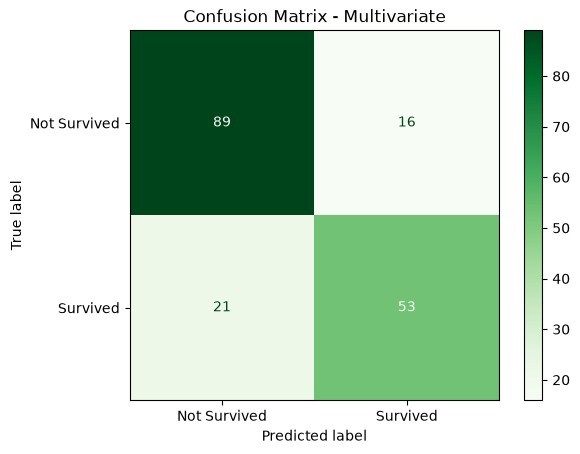

In [23]:
cm_multi = confusion_matrix(y_test, y_pred_multi)
ConfusionMatrixDisplay(cm_multi, display_labels=['Not Survived', 'Survived']).plot(cmap='Greens')
plt.title('Confusion Matrix - Multivariate')
plt.show()

**Q20.** Compare the accuracy of the univariate model (Section 2) with the multivariate model (Section 3). Which one performs better, and why do you think that is?

In [24]:
print(f"Univariate  accuracy: {acc_uni:.4f}")
print(f"Multivariate accuracy: {acc_multi:.4f}")

Univariate  accuracy: 0.6536
Multivariate accuracy: 0.7933
